---
title: "RL Chapter 1"
author: "Fabian"
date: "2026-01-10"
categories: ["Reinforcement Learning"]
image: thumbnail.png
format:
  html:
    code-fold: false
    toc: true3
jupyter: python3
draft: False
---

---
title: "Summary of Chapter 1: The Reinforcement Learning Problem"
author: "Fabian"
date: "2026-01-10"
categories: [RL]
format:
  html:
    code-fold: false
    toc: true
jupyter: python3
draft: False
---

### Summary of Chapter 1: The Reinforcement Learning Problem

Notes based on the book Sutton, R. S., & Barto, A. G. (2018). Reinforcement learning: An introduction. MIT press.

Chapter 1 introduces the fundamental concepts of Reinforcement Learning (RL) as a computational approach to learning from interaction.

**1. The Nature of RL**

* **Learning by Interaction:** Unlike other machine learning paradigms, RL focuses on an agent interacting with an environment to achieve a goal. The agent senses the state of the environment, takes actions, and receives rewards.


* **Trial-and-Error:** The agent is not told which actions to take (as in supervised learning). Instead, it must discover which actions yield the most reward by trying them.


* **Exploration vs. Exploitation:** A central challenge is the trade-off between *exploiting* known actions that yield reward and *exploring* new actions that might yield higher reward in the future. The agent cannot exclusively do either and succeed.



2. Key Elements of an RL System 

* **Policy ():** Defines the agent's behavior at a given time; a mapping from perceived states to actions.
* **Reward Signal ():** Defines the goal. It is a single number sent by the environment indicating the immediate goodness of an event. The agent tries to maximize the total reward over the long run.
* **Value Function ():** Specifies what is good in the *long run*. The value of a state is the total amount of reward an agent can expect to accumulate starting from that state. While rewards are primary, values are what we use to make decisions.


* 
**Model of the Environment (Optional):** Mimics the behavior of the environment (e.g., predicting the next state and reward) to allow for planning.



3. The Tic-Tac-Toe Example 
The chapter uses Tic-Tac-Toe to contrast RL with other methods:

* **Evolutionary Methods:** Might search the space of policies directly, ignoring the internal structure of the game (win/loss only).
* **Value Function Method (RL):** Learns a value for every possible state (probability of winning from that state).
* **Greedy moves:** Most of the time, the agent moves to the state with the highest estimated value.
* **Exploratory moves:** Occasionally, it chooses a random move to learn about new states.
* **Learning Rule:** When moving from state  to , the value of  is updated to be closer to the value of :


This is a *Temporal-Difference (TD)* learning update.





---

### Python Implementation: Tic-Tac-Toe Agent

This code implements the reinforcement learning agent described in Section 1.5. It learns to play Tic-Tac-Toe by playing against itself (self-play), updating its value function estimates based on the outcome of moves.


Training Agents...
Rounds 0
Rounds 1000
Rounds 2000
Rounds 3000
Rounds 4000


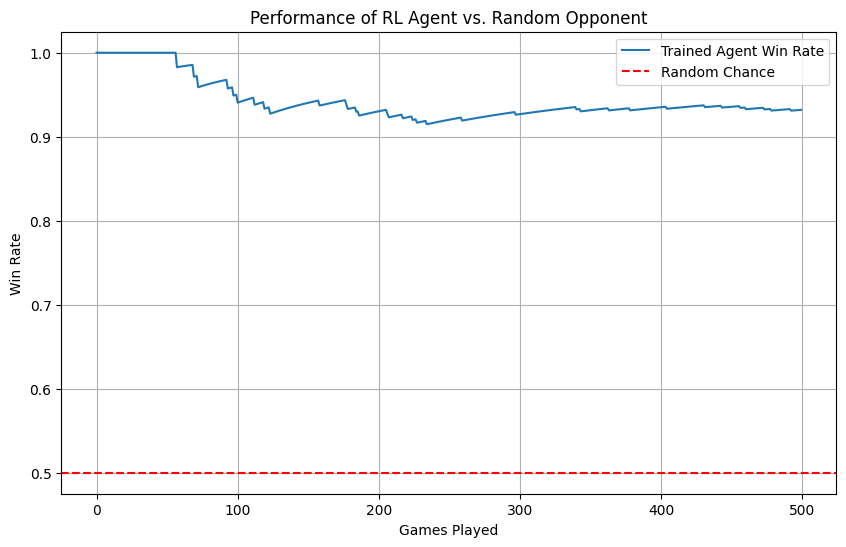

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pickle

# --- Game Environment ---
class TicTacToe:
    def __init__(self):
        self.board = np.zeros((3, 3))
        self.p1 = 1  # Agent 1 (X)
        self.p2 = -1 # Agent 2 (O)
        self.is_end = False
        self.board_hash = None
        self.turn = 1

    def get_hash(self):
        # Hash the board state to store in the value table
        self.board_hash = str(self.board.reshape(3 * 3))
        return self.board_hash

    def winner(self):
        # Check rows, cols, diagonals
        for i in range(3):
            if sum(self.board[i, :]) == 3 or sum(self.board[:, i]) == 3:
                self.is_end = True
                return 1
            if sum(self.board[i, :]) == -3 or sum(self.board[:, i]) == -3:
                self.is_end = True
                return -1
        
        diag_sum1 = sum([self.board[i, i] for i in range(3)])
        diag_sum2 = sum([self.board[i, 2 - i] for i in range(3)])
        
        if diag_sum1 == 3 or diag_sum2 == 3:
            self.is_end = True
            return 1
        if diag_sum1 == -3 or diag_sum2 == -3:
            self.is_end = True
            return -1

        if len(self.available_positions()) == 0:
            self.is_end = True
            return 0  # Draw
            
        self.is_end = False
        return None

    def available_positions(self):
        positions = []
        for i in range(3):
            for j in range(3):
                if self.board[i, j] == 0:
                    positions.append((i, j))
        return positions

    def update_state(self, position):
        self.board[position] = self.turn
        self.turn = -1 if self.turn == 1 else 1

    def give_reward(self):
        result = self.winner()
        if result == 1:
            return 1, 0 # P1 wins
        elif result == -1:
            return 0, 1 # P2 wins
        else:
            return 0.1, 0.5 # Draw (slight reward for not losing)

    def reset(self):
        self.board = np.zeros((3, 3))
        self.is_end = False
        self.turn = 1
        self.board_hash = None

# --- RL Agent ---
class Agent:
    def __init__(self, name, exp_rate=0.3):
        self.name = name
        self.states = []  # Record all positions taken
        self.lr = 0.2     # Learning Rate (Alpha)
        self.exp_rate = exp_rate # Epsilon
        self.decay_gamma = 0.9
        self.states_value = {}  # State -> Value mapping

    def get_hash(self, board):
        return str(board.reshape(3 * 3))

    def choose_action(self, positions, current_board, symbol):
        if np.random.uniform(0, 1) <= self.exp_rate:
            # Exploration: choose random action
            idx = np.random.choice(len(positions))
            action = positions[idx]
        else:
            # Exploitation: choose greedy action (max value)
            value_max = -999
            for p in positions:
                next_board = current_board.copy()
                next_board[p] = symbol
                next_board_hash = self.get_hash(next_board)
                value = 0 if self.states_value.get(next_board_hash) is None else self.states_value.get(next_board_hash)
                if value >= value_max:
                    value_max = value
                    action = p
        return action

    # Store state history
    def add_state(self, state):
        self.states.append(state)

    # Update Value Function (Backpropagation of Reward)
    # V(s) = V(s) + alpha * (V(s') - V(s))
    def feed_reward(self, reward):
        for st in reversed(self.states):
            if self.states_value.get(st) is None:
                self.states_value[st] = 0
            # TD Update rule
            self.states_value[st] += self.lr * (self.decay_gamma * reward - self.states_value[st])
            reward = self.states_value[st]
        self.states = [] # Clear history after game

    def reset(self):
        self.states = []

# --- Training and Simulation ---
def train(rounds=1000):
    p1 = Agent("p1")
    p2 = Agent("p2")
    env = TicTacToe()
    
    print("Training Agents...")
    for i in range(rounds):
        if i % 1000 == 0:
            print("Rounds {}".format(i))
            
        while not env.is_end:
            # Player 1 Move
            positions = env.available_positions()
            p1_action = p1.choose_action(positions, env.board, 1)
            env.update_state(p1_action)
            board_hash = env.get_hash()
            p1.add_state(board_hash)

            win = env.winner()
            if win is not None:
                reward_1, reward_2 = env.give_reward()
                p1.feed_reward(reward_1)
                p2.feed_reward(reward_2)
                p1.reset()
                p2.reset()
                env.reset()
                break

            # Player 2 Move
            positions = env.available_positions()
            p2_action = p2.choose_action(positions, env.board, -1)
            env.update_state(p2_action)
            board_hash = env.get_hash()
            p2.add_state(board_hash)

            win = env.winner()
            if win is not None:
                reward_1, reward_2 = env.give_reward()
                p1.feed_reward(reward_1)
                p2.feed_reward(reward_2)
                p1.reset()
                p2.reset()
                env.reset()
                break
    return p1

# --- Evaluate Performance ---
def evaluate(p1, rounds=200):
    # p1 plays against a random player
    env = TicTacToe()
    random_p = Agent("random", exp_rate=1.0) # Always explores (random)
    p1.exp_rate = 0 # Turn off exploration for evaluation
    
    win_history = []
    
    for i in range(rounds):
        while not env.is_end:
            # P1 (Trained)
            positions = env.available_positions()
            p1_action = p1.choose_action(positions, env.board, 1)
            env.update_state(p1_action)
            
            if env.winner() is not None:
                if env.winner() == 1: win_history.append(1)
                else: win_history.append(0)
                env.reset()
                break
                
            # Random Player
            positions = env.available_positions()
            p2_action = random_p.choose_action(positions, env.board, -1)
            env.update_state(p2_action)
            
            if env.winner() is not None:
                if env.winner() == -1: win_history.append(0) # Loss
                else: win_history.append(0.5) # Draw
                env.reset()
                break
    return win_history

# Run Training
p1_agent = train(5000)

# Run Evaluation vs Random Agent
history = evaluate(p1_agent, 500)

# --- Visualization ---
cumulative_wins = np.cumsum(history)
win_rate = cumulative_wins / (np.arange(len(history)) + 1)

plt.figure(figsize=(10, 6))
plt.plot(win_rate, label='Trained Agent Win Rate')
plt.axhline(y=0.5, color='r', linestyle='--', label='Random Chance')
plt.title('Performance of RL Agent vs. Random Opponent')
plt.xlabel('Games Played')
plt.ylabel('Win Rate')
plt.legend()
plt.grid(True)
plt.show()


### Explanation of the Code Concepts

1. **State Representation:** The `get_hash` method converts the 3x3 board into a unique string. This serves as the "State"  in the RL framework.
2. **Value Table:** `self.states_value` is a dictionary acting as the Value Function . It maps every board state hash to a numerical value representing the probability of winning.
3. **Exploration vs. Exploitation:** In `choose_action`, the `exp_rate` (epsilon) determines if the agent explores (random move) or exploits (chooses the move leading to the state with the highest value in `states_value`).
4. **Temporal Difference Update:** The `feed_reward` function implements the core math from Chapter 1. It iterates backward through the game history and updates the value of the previous state to be closer to the current reward (or next state's value): `self.states_value[st] += self.lr * (self.decay_gamma * reward - self.states_value[st])`.

#### So why is the win rate getting worse?

the agent is playing against iself and the code  pennalizes the draw

```python
# From the provided evaluate function:
if env.winner() == 1: win_history.append(1) # Win = 1.0
else: win_history.append(0)                 # Draw = 0.0 (on P1's turn)
```

Lets plot the wins and draw to see if that is the case. lets try 10,000 rounds.

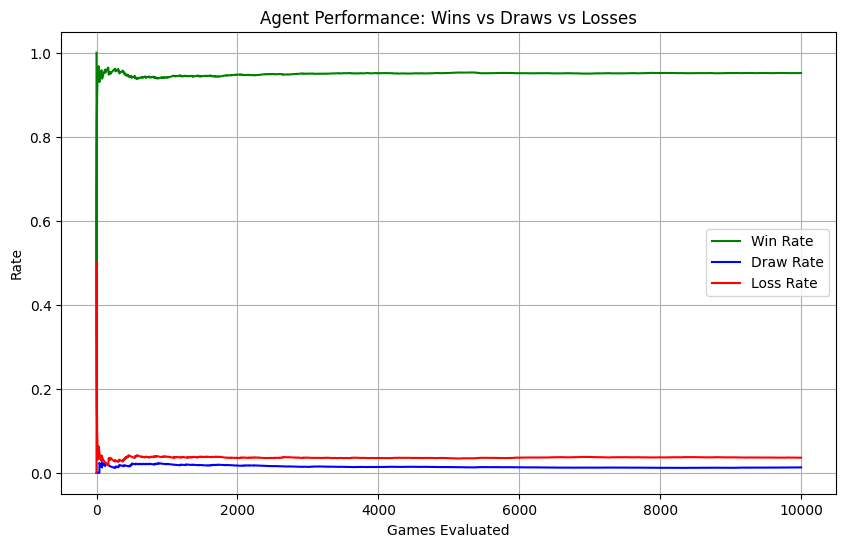

In [3]:
def evaluate_detailed(p1, rounds=500):
    env = TicTacToe()
    random_p = Agent("random", exp_rate=1.0)
    p1.exp_rate = 0 
    
    results = [] # 1 for win, 0 for draw, -1 for loss
    
    for i in range(rounds):
        while not env.is_end:
            # P1 (Trained)
            positions = env.available_positions()
            p1_action = p1.choose_action(positions, env.board, 1)
            env.update_state(p1_action)
            
            win = env.winner()
            if win is not None:
                results.append(win) # 1=Win, 0=Draw, -1=Loss
                env.reset()
                break
                
            # Random Opponent
            positions = env.available_positions()
            p2_action = random_p.choose_action(positions, env.board, -1)
            env.update_state(p2_action)
            
            win = env.winner()
            if win is not None:
                results.append(win)
                env.reset()
                break
    return results

# ... [After Training] ...

game_results = evaluate_detailed(p1_agent, 10000)

# Process Results
wins = [1 if r == 1 else 0 for r in game_results]
draws = [1 if r == 0 else 0 for r in game_results]
losses = [1 if r == -1 else 0 for r in game_results]

# Cumulative Rates
games_played = np.arange(1, len(game_results) + 1)
win_rate = np.cumsum(wins) / games_played
draw_rate = np.cumsum(draws) / games_played
loss_rate = np.cumsum(losses) / games_played

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(win_rate, label='Win Rate', color='green')
plt.plot(draw_rate, label='Draw Rate', color='blue')
plt.plot(loss_rate, label='Loss Rate', color='red')
plt.title('Agent Performance: Wins vs Draws vs Losses')
plt.xlabel('Games Evaluated')
plt.ylabel('Rate')
plt.legend()
plt.grid(True)
plt.show()